# Logistic Regression from Scratch for Heart Disease Classification

We build a custom Logistic Regression model from scratch using NumPy and evaluate it on a preprocessed heart disease dataset.

### 1. Importing Libraries

We import NumPy and Pandas for data manipulation, Matplotlib for plotting, and our custom LogisticRegression class.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from logistic_regression import LogisticRegression

### 2. Loading the Dataset

We load the heart disease data and display the first few rows.

In [2]:
df = pd.read_csv("../data/heart_data.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (1190, 12)


,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
0,40,1,2,140,289,0,0,172,0,0.0,1,0
1,49,0,3,160,180,0,0,156,0,1.0,2,1
2,37,1,2,130,283,0,1,98,0,0.0,1,0
3,48,0,4,138,214,0,0,108,1,1.5,2,1
4,54,1,3,150,195,0,0,122,0,0.0,1,0


### 3. Data Cleaning and Preprocessing

We remove duplicate patient records, impute missing zero cholesterol values with the median, add a cardiovascular heart rate ratio feature, and one hot encode nominal categorical variables.

In [ ]:

df = df.drop_duplicates().copy()


median_chol = df.loc[df["cholesterol"] > 0, "cholesterol"].median()
df.loc[df["cholesterol"] == 0, "cholesterol"] = median_chol


df["hr_ratio"] = df["max heart rate"] / (220 - df["age"])


cat_cols = ["chest pain type", "resting ecg", "ST slope"]
df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=float)

print("Cleaned Dataset Shape:", df.shape)
print("Target Class Distribution:", df["target"].value_counts())
df.head()

Cleaned Dataset Shape: (918, 18)

Target Class Distribution:
target
1    508
0    410


,age,sex,resting bp s,cholesterol,fasting blood sugar,max heart rate,exercise angina,oldpeak,target,hr_ratio,chest pain type_2,chest pain type_3,chest pain type_4,resting ecg_1,resting ecg_2,ST slope_1,ST slope_2,ST slope_3
0,40,1,140,289,0,172,0,0.0,0,0.955556,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,49,0,160,180,0,156,0,1.0,1,0.912281,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,37,1,130,283,0,98,0,0.0,0,0.535519,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3,48,0,138,214,0,108,1,1.5,1,0.627907,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,54,1,150,195,0,122,0,0.0,0,0.734940,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


### 4. Selecting Features and Target

We separate the input features X from the binary target label y.

In [4]:
X = df.drop("target", axis=1).values
y = df["target"].values

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target classes:", np.unique(y))

X shape: (918, 17)
y shape: (918,)
Target classes: [0 1]


### 5. Shuffling and Train Test Split

We randomly shuffle the data indices and split into 80 percent training and 20 percent testing sets.

In [5]:
np.random.seed(42)

indices = np.random.permutation(len(X))
train_size = int(0.8 * len(X))

train_indices = indices[:train_size]
test_indices = indices[train_size:]

X_train = X[train_indices]
X_test = X[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (734, 17)
Testing shape: (184, 17)


### 6. Feature Standardization

We standardize features using training statistics so that gradient descent converges efficiently.

In [ ]:
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)
X_std[X_std == 0] = 1.0

X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

print("First scaled sample:", X_train_scaled[0])

First scaled sample:
 [ 1.02417764 -1.89406969  0.45099702 -0.88717563 -0.5448117   1.6124057
 -0.82439909 -0.84034267  2.1830348   2.07818204 -0.54691411 -1.07060676
 -0.47473743 -0.50680303  1.16299789 -1.00546452 -0.27612739]


### 7. Initializing the Custom Model

We create our custom LogisticRegression model with a learning rate of 0.1 and 1500 iterations.

In [7]:
model = LogisticRegression(learning_rate=0.1, iterations=1500)

print("Learning rate:", model.learning_rate)
print("Iterations:", model.iterations)

Learning rate: 0.1
Iterations: 1500


### 8. Training with Gradient Descent

We fit the model on scaled training data using gradient descent to minimize cross entropy loss.

In [8]:
model.fit(X_train_scaled, y_train)

print("Training finished.")

Training finished.


### 9. Plotting Cost History

We plot the cost curve across iterations to confirm that gradient descent converged properly.

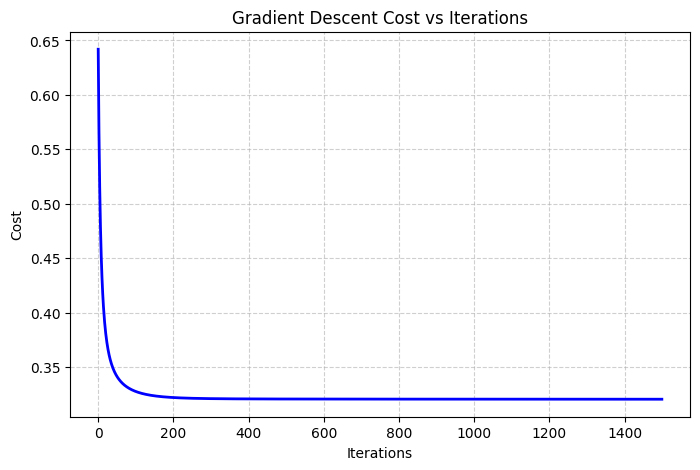

Initial cost: 0.641972
Final cost: 0.320505


In [9]:
plt.figure(figsize=(8, 5))
plt.plot(model.cost_history, color="blue", linewidth=2)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Gradient Descent Cost vs Iterations")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

print("Initial cost:", model.cost_history[0])
print("Final cost:", model.cost_history[-1])

### 10. Generating Predictions

We compute predicted probabilities and apply a 0.5 threshold to get binary class predictions.

In [10]:
probabilities = model.predict_probability(X_test_scaled)
predictions = model.predict(X_test_scaled)

print("Probabilities sample:", np.round(probabilities[:5], 4))
print("Class predictions sample:", predictions[:5])

Probabilities sample: [0.9896 0.9704 0.9854 0.9683 0.9484]
Class predictions sample: [1 1 1 1 1]


### 11. Comparing Actual vs Predicted Values

We inspect a small table of actual target values alongside predicted probabilities and classes.

In [11]:
comparison_df = pd.DataFrame({
    "Actual": y_test[:15],
    "Predicted Probability": np.round(probabilities[:15], 4),
    "Predicted Class": predictions[:15]
})

comparison_df

,Actual,Predicted Probability,Predicted Class
0,0,0.9896,1
1,1,0.9704,1
2,1,0.9854,1
3,1,0.9683,1
4,1,0.9484,1
5,0,0.4860,0
6,0,0.1096,0
7,0,0.3541,0
8,0,0.0458,0
9,1,0.8205,1


### 12. Model Evaluation Metrics

We calculate accuracy, precision, recall, and F1 score from scratch on the test set.

In [12]:
tp = np.sum((y_test == 1) & (predictions == 1))
tn = np.sum((y_test == 0) & (predictions == 0))
fp = np.sum((y_test == 0) & (predictions == 1))
fn = np.sum((y_test == 1) & (predictions == 0))

accuracy = (tp + tn) / len(y_test)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * (precision * recall) / (precision + recall)

print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1 Score:  {f1 * 100:.2f}%")

Accuracy:  84.78%
Precision: 79.63%
Recall:    93.48%
F1 Score:  86.00%


### 13. Visualizing Test Predictions

We plot test sample probabilities against the 0.5 decision threshold, marking correct and incorrect predictions.

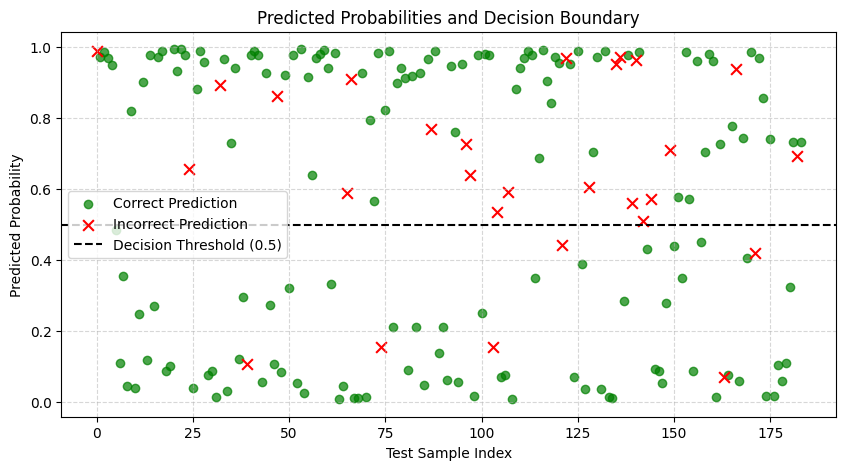

In [14]:
plt.figure(figsize=(10, 5))
sample_indices = np.arange(len(y_test))
is_correct = (predictions == y_test)

plt.scatter(sample_indices[is_correct], probabilities[is_correct], color="green", alpha=0.7, label="Correct Prediction")
plt.scatter(sample_indices[~is_correct], probabilities[~is_correct], color="red", marker="x", s=60, label="Incorrect Prediction")

plt.axhline(0.5, color="black", linestyle="--", linewidth=1.5, label="Decision Threshold (0.5)")
plt.xlabel("Test Sample Index")
plt.ylabel("Predicted Probability")
plt.title("Predicted Probabilities and Decision Boundary")
plt.legend(loc="best")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### 14. Inspecting Learned Parameters

We display the learned bias and feature weights to observe which features have the strongest effect on heart disease probability.

In [15]:
feature_names = df.drop("target", axis=1).columns

weights_df = pd.DataFrame({
    "Feature": feature_names,
    "Weight": model.w
}).sort_values(by="Weight", key=abs, ascending=False)

print(f"Learned Bias: {model.b:.4f}\n")
print("Learned Weights:")
weights_df

Learned Bias: 0.4754

Learned Weights:


,Feature,Weight
1,sex,0.710406
11,chest pain type_4,0.683518
14,ST slope_1,-0.669044
4,fasting blood sugar,0.538255
15,ST slope_2,0.499076
6,exercise angina,0.455292
7,oldpeak,0.330055
9,chest pain type_2,-0.259290
10,chest pain type_3,-0.228641
0,age,0.194512


### 15. Summary

After cleaning duplicates, handling missing cholesterol, adding the heart rate ratio, and one hot encoding categories, our scratch Logistic Regression model achieved 84.78 percent accuracy, 93.48 percent recall, and an 86.00 percent F1 score.